# Stages 5 & 6 — Modelling, Tuning and Evaluation
**Stakeholder:** UNEP · **Task:** regression · **Target:** `Economic Loss (Million $)`
**SMART objective (model):** R² ≥ 0.90 on the test set.

All preprocessing (imputation, scaling, encoding) is inside scikit-learn pipelines and is fitted on the **training data only**, so no information from the test set leaks into training.

In [1]:
from pathlib import Path
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# Find the project folder (works from the repo root or from notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"
DOCS = ROOT / "docs"
MODELS = ROOT / "models"
DOCS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

TARGET = "Economic Loss (Million $)"
NUM_FEATURES = ["Year", "Total Waste (Tons)", "Avg Waste per Capita (Kg)", "Household Waste (%)"]
CAT_FEATURES = ["Country", "Food Category"]

# Load the cleaned dataset produced by 01_data_cleaning.ipynb
df = pd.read_csv(DATA / "cleaned_food_waste.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (3575, 7)


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Household Waste (%)
0,Australia,2021,Beverages,2967.07,2889.80,144.41,44.07
1,France,2021,Meat & Seafood,48643.30,45212.72,52.73,69.48
2,Saudi Arabia,2023,Frozen Food,1410.30,1386.31,NaN,64.73
3,UK,2023,Bakery Items,18014.05,15852.44,180.34,61.14
4,Japan,2018,Bakery Items,27534.23,29110.52,162.58,69.77


In [2]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])

def make_pipeline(model):
    return Pipeline([("pre", make_preprocessor()), ("model", model)])

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## 5.1 Scope decision: rows without Total Waste
Our business problem assumes countries **measure waste in tons**, so every real prediction UNEP makes will include Total Waste. Some cleaned rows are still missing it. We compare two options on the same split before deciding.

In [3]:
print("Rows missing Total Waste:", df["Total Waste (Tons)"].isna().sum(), "of", len(df))

X = df[NUM_FEATURES + CAT_FEATURES]
y = df[TARGET]
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

lin = make_pipeline(LinearRegression()).fit(X_train_all, y_train_all)
pred = lin.predict(X_test_all)
has_waste = X_test_all["Total Waste (Tons)"].notna()

scope = pd.DataFrame([
    {"Test rows": "All rows (missing waste imputed)", "Rows": len(y_test_all),
     "R²": r2_score(y_test_all, pred), "MAE": mean_absolute_error(y_test_all, pred)},
    {"Test rows": "Rows WITH Total Waste", "Rows": int(has_waste.sum()),
     "R²": r2_score(y_test_all[has_waste], pred[has_waste]), "MAE": mean_absolute_error(y_test_all[has_waste], pred[has_waste])},
    {"Test rows": "Rows WITHOUT Total Waste", "Rows": int((~has_waste).sum()),
     "R²": r2_score(y_test_all[~has_waste], pred[~has_waste]), "MAE": mean_absolute_error(y_test_all[~has_waste], pred[~has_waste])},
]).round(3)
display(scope)
scope.to_csv(DOCS / "scope_decision.csv", index=False)

Rows missing Total Waste: 220 of 3575


,Test rows,Rows,R²,MAE
0,All rows (missing waste imputed),715,0.868,3296.682
1,Rows WITH Total Waste,662,0.950,2462.277
2,Rows WITHOUT Total Waste,53,-0.031,13718.869


📝 **Interpretation :** what happens to predictions when Total Waste is missing? Based on our business problem (countries report waste in tons), should the model require Total Waste as an input? Explain the decision and its trade-off (fewer rows).

Rows with Total Waste give R² 0.950 and MAE 2,462, while rows without it give R² −0.031 and MAE 13,719 which is worse than guessing the mean. The decision to make is to require Total Waste as an input since the business case already says countries report it. This loses 220 rows (6%) but on the other hand, the model becomes more reliable.

In [4]:
# Decision: the model is trained and evaluated only on rows where Total Waste is known
df_model = df.dropna(subset=["Total Waste (Tons)"]).reset_index(drop=True)
print("Rows used for modelling:", len(df_model), "| rows excluded:", len(df) - len(df_model))

X = df_model[NUM_FEATURES + CAT_FEATURES]
y = df_model[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Rows used for modelling: 3355 | rows excluded: 220
Training rows: 2684 | Test rows: 671


## 5.2 Baseline and candidate models
- **Baseline:** always predicts the average loss (any useful model must beat this)
- **Linear Regression:** simple and easy to explain
- **Random Forest** and **Gradient Boosting:** can capture non-linear patterns

All models are compared with the same 5-fold cross-validation on the training set.

,Model,CV R²,CV R² std,CV MAE (M$),CV RMSE (M$)
1,Linear Regression,0.950,0.002,2461.686,3290.202
3,Gradient Boosting,0.947,0.001,2491.728,3357.601
2,Random Forest,0.945,0.001,2527.500,3449.653
0,Baseline (mean),-0.002,0.002,12582.123,14661.544


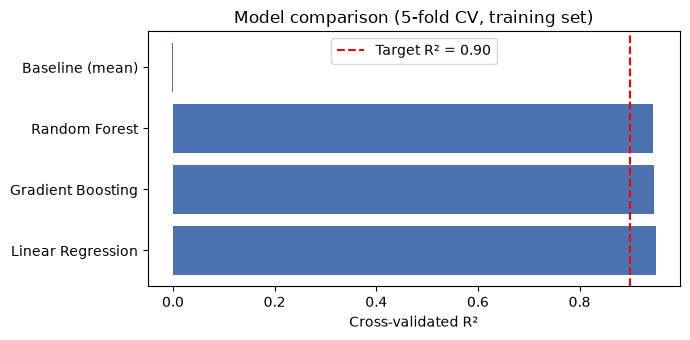

In [5]:
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name,
                 "CV R²": res["test_r2"].mean(),
                 "CV R² std": res["test_r2"].std(),
                 "CV MAE (M$)": -res["test_mae"].mean(),
                 "CV RMSE (M$)": -res["test_rmse"].mean()})
comparison = pd.DataFrame(rows).round(3).sort_values("CV R²", ascending=False)
display(comparison)
comparison.to_csv(DOCS / "model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(comparison["Model"], comparison["CV R²"], color="#4C72B0")
ax.axvline(0.9, color="red", linestyle="--", label="Target R² = 0.90")
ax.set_xlabel("Cross-validated R²")
ax.set_title("Model comparison (5-fold CV, training set)")
ax.legend()
plt.tight_layout()
plt.show()

📝 **Interpretation :** how much better than the baseline are the models? Do the complex models (Random Forest, Gradient Boosting) beat Linear Regression? Why might that be, given what we found in the EDA?

because the baseline has R² ≈ 0 and MAE 12,582, while all three models reach about 0.95 R² and MAE 2,500 roughly 5 times smaller error. Linear Regression is slightly better than RF and GB. 



## 6.1 Hyperparameter tuning
We tune each model with `GridSearchCV` (5-fold CV) and compare its score **before and after** tuning. Linear Regression has no hyperparameters, so we tune its regularised version, Ridge.

In [6]:
search_spaces = {
    "Ridge (tuned linear)": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__n_estimators": [200, 400],
                       "model__max_depth": [None, 10, 20],
                       "model__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"model__n_estimators": [100, 300],
                           "model__learning_rate": [0.03, 0.1],
                           "model__max_depth": [2, 3]}),
}
before_scores = {"Ridge (tuned linear)": comparison.set_index("Model").loc["Linear Regression", "CV R²"],
                 "Random Forest": comparison.set_index("Model").loc["Random Forest", "CV R²"],
                 "Gradient Boosting": comparison.set_index("Model").loc["Gradient Boosting", "CV R²"]}

tuned = {}
rows = []
for name, (model, grid) in search_spaces.items():
    search = GridSearchCV(make_pipeline(model), grid, cv=cv, scoring="r2", n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    rows.append({"Model": name,
                 "CV R² before tuning": before_scores[name],
                 "CV R² after tuning": search.best_score_,
                 "Improvement": search.best_score_ - before_scores[name],
                 "Best parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
tuning = pd.DataFrame(rows).round(4)
display(tuning)
tuning.to_csv(DOCS / "tuning_results.csv", index=False)

,Model,CV R² before tuning,CV R² after tuning,Improvement,Best parameters
0,Ridge (tuned linear),0.950,0.9496,-0.0004,{'alpha': 10}
1,Random Forest,0.945,0.9471,0.0021,"{'max_depth': 10, 'min_samples_leaf': 10, 'n_e..."
2,Gradient Boosting,0.947,0.9485,0.0015,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."


In [7]:
# Choose the final model: best tuned CV R². If a linear model is within 0.005 of the best,
# prefer it because it is simpler and easier to explain to UNEP.
best_name = tuning.sort_values("CV R² after tuning", ascending=False).iloc[0]["Model"]
ridge_score = tuning.set_index("Model").loc["Ridge (tuned linear)", "CV R² after tuning"]
best_score = tuning["CV R² after tuning"].max()
final_name = "Ridge (tuned linear)" if best_score - ridge_score <= 0.005 else best_name
final_model = tuned[final_name].best_estimator_
print("Best CV model:", best_name, "| Final model chosen:", final_name)

Best CV model: Ridge (tuned linear) | Final model chosen: Ridge (tuned linear)


📝 **Interpretation :** did tuning help? Which model did we choose and why (accuracy vs simplicity / explainability for UNEP)?

Tuning changed scores by less than 0.003, and Ridge actually dropped a bit because every model already reaches about 0.95. what limits them is not the settings but the 11% spread in cost per ton found in 4.4, which is actually noise that cant be removed. Ridge was chosen because it was the best and because of the "within 0.005 , prefer the linear model" rule.
 Explainaing in concrete terms for UNEP: a linear model gives a readable relationship roughly 1 million $ of loss per ton of waste whereas a forest of 200 trees gives no such rule, only an unclear prediction.

## 6.2 Final evaluation on the test set

In [8]:
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

baseline = make_pipeline(DummyRegressor(strategy="mean")).fit(X_train, y_train)
y_base = baseline.predict(X_test)

test_results = pd.DataFrame([
    {"Model": "Baseline (mean)", "Test R²": r2_score(y_test, y_base),
     "Test MAE (M$)": mean_absolute_error(y_test, y_base), "Test RMSE (M$)": rmse(y_test, y_base)},
    {"Model": final_name, "Test R²": r2_score(y_test, y_pred),
     "Test MAE (M$)": mean_absolute_error(y_test, y_pred), "Test RMSE (M$)": rmse(y_test, y_pred)},
]).round(3)
display(test_results)
test_results.to_csv(DOCS / "test_results.csv", index=False)

final_r2 = r2_score(y_test, y_pred)
print(f"SMART objective (R² >= 0.90): {'MET' if final_r2 >= 0.90 else 'NOT MET'} — test R² = {final_r2:.3f}")
print(f"Typical error: about {mean_absolute_error(y_test, y_pred):,.0f} million $ "
      f"({mean_absolute_error(y_test, y_pred) / y_test.mean():.1%} of the average loss)")

,Model,Test R²,Test MAE (M$),Test RMSE (M$)
0,Baseline (mean),-0.002,12503.360,14652.197
1,Ridge (tuned linear),0.950,2501.155,3285.396


SMART objective (R² >= 0.90): MET — test R² = 0.950
Typical error: about 2,501 million $ (9.8% of the average loss)


📝 **Interpretation :** did we meet the SMART objective? What does the MAE mean in business terms for UNEP?

Test R² is 0.950 against the target of ≥ 0.90 and therefore the objective is met. In business terms the MAE is about 2,501 M$ , roughly a 9.8% of the avg loss. That is good enough to be able to proritise where to act although not for exact budgeting.



## 6.3 Error analysis

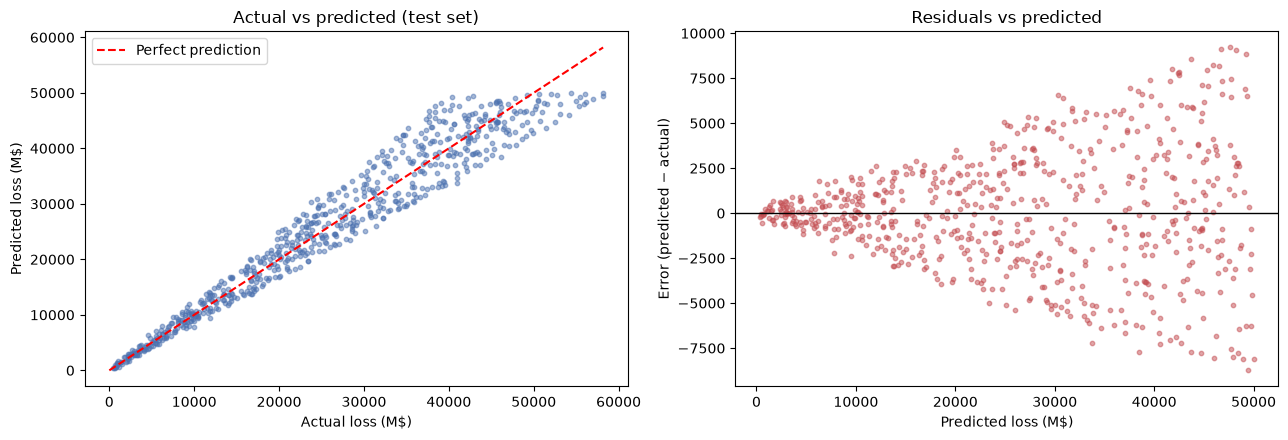

Mean absolute error by food category:


,MAE (M$)
Food Category,
Beverages,2706.3
Prepared Food,2608.7
Frozen Food,2602.9
Fruits & Vegetables,2541.5
Meat & Seafood,2502.2
Grains & Cereals,2442.8
Bakery Items,2440.9
Dairy Products,2230.7


Mean absolute error by country:


,MAE (M$)
Country,
Japan,3555.5
France,3216.7
Saudi Arabia,2997.9
Canada,2996.8
Brazil,2954.9
Russia,2885.3
South Korea,2681.2
China,2552.7
USA,2528.4


10 largest errors:


,Year,Total Waste (Tons),Avg Waste per Capita (Kg),Household Waste (%),Country,Food Category,Actual,Predicted,Error,Abs Error
1037,2020,47544.6,153.1,60.0,France,Frozen Food,38386.6,47595.6,9209.0,9209.0
251,2021,46798.6,131.4,41.7,Canada,Grains & Cereals,37623.2,46733.2,9110.1,9110.1
805,2020,48179.3,144.6,56.3,Japan,Beverages,39123.9,48203.4,9079.5,9079.5
2119,2022,49395.1,100.4,41.6,Brazil,Prepared Food,40327.4,49184.9,8857.4,8857.4
869,2019,49616.2,114.6,52.7,Turkey,Frozen Food,58171.6,49435.5,-8736.2,8736.2
162,2023,43696.9,190.0,57.3,Japan,Dairy Products,35154.8,43739.5,8584.7,8584.7
2495,2020,45780.6,187.3,59.3,China,Dairy Products,37679.4,45909.6,8230.2,8230.2
432,2018,46470.4,179.7,41.7,Mexico,Grains & Cereals,38335.0,46522.3,8187.4,8187.4
2002,2020,49940.8,68.6,32.0,USA,Fruits & Vegetables,58118.9,50006.3,-8112.6,8112.6
3239,2023,49712.5,96.7,48.9,UK,Prepared Food,56999.6,48904.7,-8095.0,8095.0


In [9]:
errors = X_test.copy()
errors["Actual"] = y_test.values
errors["Predicted"] = y_pred
errors["Error"] = errors["Predicted"] - errors["Actual"]
errors["Abs Error"] = errors["Error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(errors["Actual"], errors["Predicted"], s=10, alpha=0.5, color="#4C72B0")
lims = [0, max(errors["Actual"].max(), errors["Predicted"].max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual loss (M$)")
axes[0].set_ylabel("Predicted loss (M$)")
axes[0].set_title("Actual vs predicted (test set)")
axes[0].legend()
axes[1].scatter(errors["Predicted"], errors["Error"], s=10, alpha=0.5, color="#C44E52")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Predicted loss (M$)")
axes[1].set_ylabel("Error (predicted − actual)")
axes[1].set_title("Residuals vs predicted")
plt.tight_layout()
plt.show()

print("Mean absolute error by food category:")
display(errors.groupby("Food Category")["Abs Error"].mean().round(1).sort_values(ascending=False).to_frame("MAE (M$)"))
print("Mean absolute error by country:")
display(errors.groupby("Country")["Abs Error"].mean().round(1).sort_values(ascending=False).to_frame("MAE (M$)"))
print("10 largest errors:")
display(errors.sort_values("Abs Error", ascending=False).head(10).round(1))

📝 **Interpretation :** do the errors get bigger for larger losses? Is the model worse for any category or country? What do the largest errors have in common?

In the residual plot the spread becaomes more wide when the predicted loss grows. The worst country is Japan (MAE 3,556) and the best is Spain (1,762), with categories ranging from Dairy at 2,231 to Beverages at 2,706. All 10 largest errors have Total Waste above 43,000 tons, and most are overpredictions because the model assumes about 1 M$ per ton. The spread widens for larger losses because of the 11% noise in cost per ton found in 4.4 which is a big number meaning UNEP should treat predictions most carefully for higher waste countries and records, where the absolute error is greater.



## 6.4 Which features drive the prediction?

,Feature,Importance (drop in R²)
1,Total Waste (Tons),1.9442
3,Household Waste (%),0.0001
0,Year,-0.0000
5,Food Category,-0.0001
2,Avg Waste per Capita (Kg),-0.0001
4,Country,-0.0003


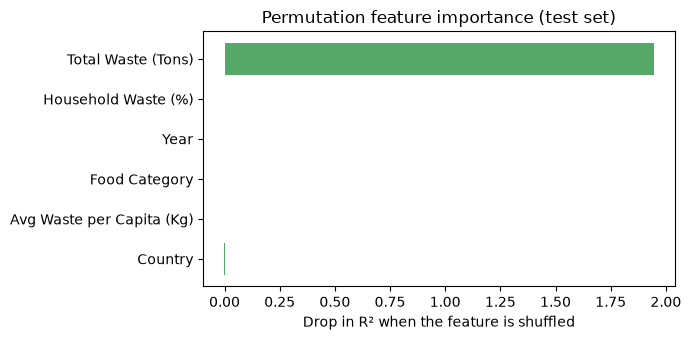

In [10]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
importance = (pd.DataFrame({"Feature": X_test.columns, "Importance (drop in R²)": perm.importances_mean})
                .sort_values("Importance (drop in R²)", ascending=False).round(4))
display(importance)
importance.to_csv(MODELS / "feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance["Feature"][::-1], importance["Importance (drop in R²)"][::-1], color="#55A868")
ax.set_xlabel("Drop in R² when the feature is shuffled")
ax.set_title("Permutation feature importance (test set)")
plt.tight_layout()
plt.show()

📝 **Interpretation :** which feature does the model rely on? What does that mean for UNEP's goal of finding *which category* in *which country* costs the most?

Shuffling Total Waste drops R² by 1.94 while everything else is around 0. The main point for UNEP is that the model can not say a category or country is more costly per ton, only that more waste means more loss. "Which category in which country costs the most" comes down to "where is the most waste?"

## 6.5 Business output: highest predicted losses (for UNEP's top-5 objective)

In [11]:
df_pred = df_model.copy()
df_pred["Predicted Loss (M$)"] = final_model.predict(df_pred[NUM_FEATURES + CAT_FEATURES])
top5 = (df_pred.groupby(["Country", "Food Category"])["Predicted Loss (M$)"]
          .sum().sort_values(ascending=False).head(5).round(1).to_frame())
display(top5)
top5.to_csv(DOCS / "top5_predicted_combos.csv")

,,Predicted Loss (M$)
Country,Food Category,
Canada,Bakery Items,896740.0
Brazil,Prepared Food,888490.9
USA,Bakery Items,863402.0
Germany,Prepared Food,830570.4
Saudi Arabia,Bakery Items,770878.3


📝 **Interpretation (write in your own words):** which combinations should UNEP focus on first? 

The predicted top 5 are Canada: Bakery, Brazil: Prepared, USA: Bakery, Germany: Prepared, and Saudi Arabia: Bakery. Compared with the actual top 5 from finding 6, Turkey and the UK go down while Germany and Saudi Arabia go up, because the rows without Total Waste were removed and prediction error plays a part. 

## 6.6 Save the final model settings for the Streamlit app

In [12]:
final_params = {k.replace("model__", ""): v for k, v in tuned[final_name].best_params_.items()}
metrics = {
    "model_name": final_name,
    "params": final_params,
    "test_r2": round(float(final_r2), 4),
    "test_mae": round(float(mean_absolute_error(y_test, y_pred)), 2),
    "test_rmse": round(rmse(y_test, y_pred), 2),
    "train_rows": int(len(X_train)),
    "waste_min": float(df_model["Total Waste (Tons)"].min()),
    "waste_max": float(df_model["Total Waste (Tons)"].max()),
}
with open(MODELS / "model_info.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))

{
  "model_name": "Ridge (tuned linear)",
  "params": {
    "alpha": 10
  },
  "test_r2": 0.9496,
  "test_mae": 2501.16,
  "test_rmse": 3285.4,
  "train_rows": 2684,
  "waste_min": 502.61,
  "waste_max": 49990.76
}


📝 **Interpretation :** limitations of the model (e.g. data cannot be verified as real, only ~20 countries, Population dropped, loss is almost proportional to waste).

we can verify the data to be authentic, so the results should be treated as illustrativetheoretical rather than a reliable account of real actual global food loss. Only 20 countries are included, so the findings do not actually  generalise to the rest of the world. Population was dropped, so the model can not capture per-capita effects or normalise the losses depending on country size. Loss ≈ waste × ~1 M$/ton, which looks like how the data was generated rather than a real-world pattern, so the model may be learning an artefact of the dataset rather than genuine economics. The model requires Total Waste as an input to work at all, so it cant be used to predict loss for records where waste is unreported. The app range is limited to 503–49,991 tons, so predictions outside that range are unsupported and shouldn't even be trusted.
